In [36]:
import pandas as pd
import matplotlib.pyplot as plt

In [37]:
df = pd.read_csv('signal_data.csv')

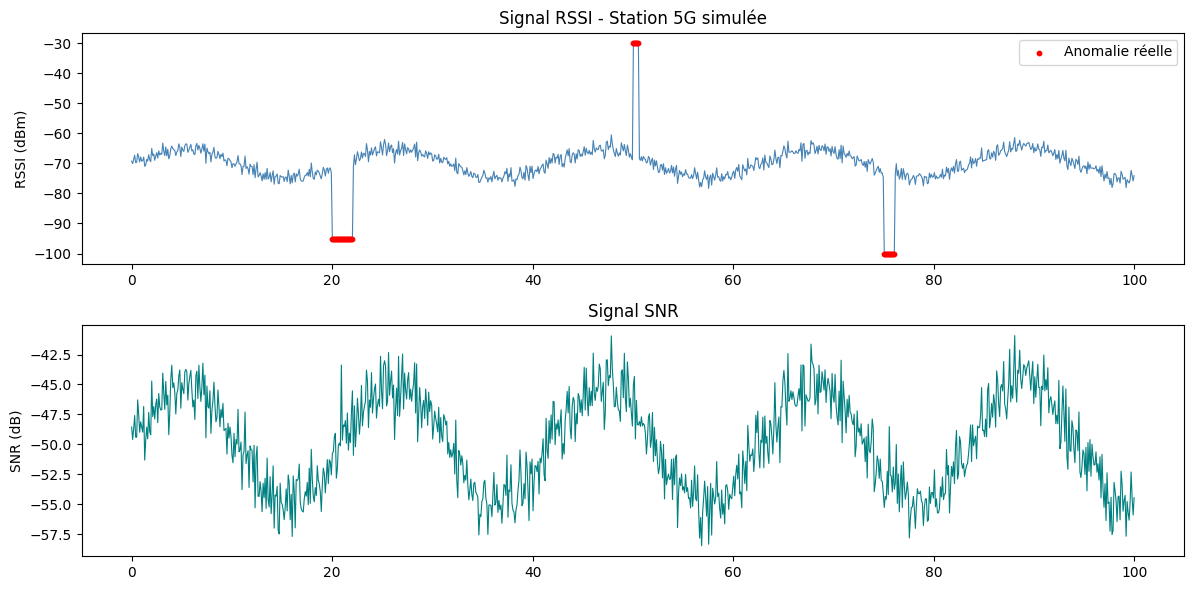

Nombre d'anomalies : 38


In [35]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6))

ax1.plot(df['time'], df['RSSI'], color='steelblue', linewidth=0.8)
anomalies = df[df['is_anomaly'] == 1]
ax1.scatter(anomalies['time'], anomalies['RSSI'],
            color='red', s=10, label='Anomalie réelle', zorder=5)
ax1.set_title('Signal RSSI - Station 5G simulée')
ax1.set_ylabel('RSSI (dBm)')
ax1.legend()

ax2.plot(df['time'], df['SNR'], color='teal', linewidth=0.8)
ax2.set_title('Signal SNR')
ax2.set_ylabel('SNR (dB)')

plt.tight_layout()
plt.savefig('signal_plot.png', dpi=150)
plt.show()
print("Nombre d'anomalies :", df['is_anomaly'].sum())

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(42)
t = np.linspace(0, 100, 1000)

# Signal RSSI normal (puissance du signal, en dBm)
rssi = -70 + 5 * np.sin(t * 0.3) + np.random.normal(0, 1.5, 1000)

# Signal SNR normal (qualité du signal)
snr = rssi + 20 + np.random.normal(0, 0.5, 1000)

In [21]:
# Injection d'anomalies (pannes simulées)
rssi[200:220] = -95   # chute soudaine (panne antenne)
rssi[500:505] = -30   # pic anormal (interférence)
rssi[750:760] = -100  # signal perdu

In [22]:
print(rssi[200:220])

[-95. -95. -95. -95. -95. -95. -95. -95. -95. -95. -95. -95. -95. -95.
 -95. -95. -95. -95. -95. -95.]


In [30]:
df = pd.DataFrame({
    'time': t,
    'RSSI': rssi,
    'SNR': snr,
    'is_anomaly': 0
})